# Base

In [28]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
df = pd.read_csv('/content/drive/MyDrive/TCC/TCC/base_processada.csv')

In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21504 entries, 0 to 21503
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   codigo_municipio             21504 non-null  int64  
 1   municipio                    21504 non-null  object 
 2   Mes_Ano                      21504 non-null  object 
 3   AIH_Aprovadas                21504 non-null  int64  
 4   Valor_Total                  21504 non-null  float64
 5   Internacoes                  21504 non-null  int64  
 6   Dias_Permanencia             21504 non-null  int64  
 7   Media_Permanencia            21502 non-null  float64
 8   Obitos                       21504 non-null  int64  
 9   ano                          21504 non-null  int64  
 10  mes                          21504 non-null  int64  
 11  codigo_ibge                  21504 non-null  int64  
 12  populacao                    21504 non-null  float64
 13  pessoas_cadunico

In [32]:
features = [
    'Media_Permanencia',
    'aih_por_internacao',
    'internacoes_1000hab',
    'obitos_1000internacoes',  # Nova variável
    'populacao',
    'razao_cadunico_pop',
    'cobertura_plano',
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado',
    'ano',
    'mes'
]

target = 'valor_medio_internacao_real'

In [33]:
colunas_modelagem = (
    ['codigo_ibge', 'municipio', 'Internacoes']
    + features
    + [target]
)

df_modelo = df[colunas_modelagem].copy()

In [34]:
print('Dimensão do dataset:')
print(df_modelo.shape)

print('\nValores ausentes:')
print(df_modelo.isna().sum().sort_values(ascending=False))

print('\nDuplicatas:')
print(df_modelo.duplicated().sum())

Dimensão do dataset:
(21504, 16)

Valores ausentes:
Media_Permanencia              2
aih_por_internacao             2
obitos_1000internacoes         2
valor_medio_internacao_real    2
Internacoes                    0
municipio                      0
internacoes_1000hab            0
codigo_ibge                    0
populacao                      0
razao_cadunico_pop             0
renda_per_capita               0
cobertura_plano                0
tx_analfabetismo               0
perc_esgotamento_adequado      0
ano                            0
mes                            0
dtype: int64

Duplicatas:
0


In [35]:
df_modelo = df_modelo.dropna(subset=[target]).copy() #os nulos são as duas observações que tiveram aih = internações = valor =0, podem ser removidas

In [36]:
print(df_modelo.shape)
print(df_modelo.isna().sum())

(21502, 16)
codigo_ibge                    0
municipio                      0
Internacoes                    0
Media_Permanencia              0
aih_por_internacao             0
internacoes_1000hab            0
obitos_1000internacoes         0
populacao                      0
razao_cadunico_pop             0
cobertura_plano                0
renda_per_capita               0
tx_analfabetismo               0
perc_esgotamento_adequado      0
ano                            0
mes                            0
valor_medio_internacao_real    0
dtype: int64


In [37]:
treino = df_modelo[df_modelo['ano'] <= 2023].copy() #treino 2018-2023
validacao = df_modelo[df_modelo['ano'] == 2024].copy() #validação para ajustes
teste = df_modelo[df_modelo['ano'] == 2025].copy()

In [38]:
X_train = treino[features].copy() #características que o modelo verá durante o treinamento
y_train = treino[target].copy() #resposta correta que o modelo verá durante o treinamento

X_val = validacao[features].copy()
y_val = validacao[target].copy()

X_test = teste[features].copy()
y_test = teste[target].copy()

In [39]:
print('Treino:', treino['ano'].min(), '-', treino['ano'].max(), X_train.shape)
print('Validação:', validacao['ano'].min(), '-', validacao['ano'].max(), X_val.shape)
print('Teste:', teste['ano'].min(), '-', teste['ano'].max(), X_test.shape)

Treino: 2018 - 2023 (16127, 12)
Validação: 2024 - 2024 (2688, 12)
Teste: 2025 - 2025 (2687, 12)


# Base anual

In [40]:
df_anual = (
    df.groupby(
        ['codigo_ibge', 'municipio', 'ano'],
        as_index=False
    )
    .agg(
        AIH_Aprovadas=('AIH_Aprovadas', 'sum'),
        Valor_Total_real=('Valor_Total_real', 'sum'),
        Internacoes=('Internacoes', 'sum'),
        Obitos=('Obitos', 'sum'),  # Nova variável
        Dias_Permanencia=('Dias_Permanencia', 'sum'),
        populacao=('populacao', 'first'),
        cobertura_plano=('cobertura_plano', 'first'),
        renda_per_capita=('renda_per_capita', 'first'),
        tx_analfabetismo=('tx_analfabetismo', 'first'),
        perc_esgotamento_adequado=('perc_esgotamento_adequado', 'first'),
        pessoas_cadunico_media=('pessoas_cadunico', 'mean')
    )
)

In [41]:
df_anual['valor_medio_internacao_real'] = (
    df_anual['Valor_Total_real']
    / df_anual['Internacoes']
)

In [42]:
df_anual['media_permanencia'] = (
    df_anual['Dias_Permanencia']
    / df_anual['Internacoes']
)

In [43]:
df_anual['internacoes_1000hab'] = ( # número de internações ocorridas durante todo o ano para cada mil habitantes
    df_anual['Internacoes']
    / df_anual['populacao']
) * 1000

In [44]:
df_anual['aih_por_internacao'] = (
    df_anual['AIH_Aprovadas']
    / df_anual['Internacoes']
)

In [45]:
df_anual['razao_cadunico_pop'] = (
    df_anual['pessoas_cadunico_media']
    / df_anual['populacao']
)

In [46]:
df_anual['obitos_1000internacoes'] = (
    df_anual['Obitos'] / df_anual['Internacoes'] * 1000
)

In [47]:
print('Dimensão:')
print(df_anual.shape)

print('\nQuantidade de municípios:')
print(df_anual['codigo_ibge'].nunique())

print('\nObservações por ano:')
print(df_anual['ano'].value_counts().sort_index())

print('\nValores ausentes:')
print(df_anual.isna().sum())

print('\nResumo do novo target:')
print(df_anual['valor_medio_internacao_real'].describe())

Dimensão:
(1792, 20)

Quantidade de municípios:
224

Observações por ano:
ano
2018    224
2019    224
2020    224
2021    224
2022    224
2023    224
2024    224
2025    224
Name: count, dtype: int64

Valores ausentes:
codigo_ibge                    0
municipio                      0
ano                            0
AIH_Aprovadas                  0
Valor_Total_real               0
Internacoes                    0
Obitos                         0
Dias_Permanencia               0
populacao                      0
cobertura_plano                0
renda_per_capita               0
tx_analfabetismo               0
perc_esgotamento_adequado      0
pessoas_cadunico_media         0
valor_medio_internacao_real    0
media_permanencia              0
internacoes_1000hab            0
aih_por_internacao             0
razao_cadunico_pop             0
obitos_1000internacoes         0
dtype: int64

Resumo do novo target:
count    1792.000000
mean     1445.913729
std       408.122867
min       583.924548


In [48]:
print(
    df_anual[
        ['razao_cadunico_pop',
         'perc_esgotamento_adequado']
    ].describe().round(3)
)

       razao_cadunico_pop  perc_esgotamento_adequado
count            1792.000                   1792.000
mean                0.773                     25.434
std                 0.112                     24.680
min                 0.329                      0.000
25%                 0.699                      3.895
50%                 0.773                     18.145
75%                 0.844                     37.635
max                 1.274                     94.850


In [49]:
df_anual.loc[
    df_anual['municipio'].str.contains(
        'Francisco Macedo',
        case=False,
        na=False
    ),
    ['municipio', 'ano', 'razao_cadunico_pop',
     'perc_esgotamento_adequado']
]

,municipio,ano,razao_cadunico_pop,perc_esgotamento_adequado
680,FRANCISCO MACEDO,2018,0.691751,0.39
681,FRANCISCO MACEDO,2019,0.663055,0.39
682,FRANCISCO MACEDO,2020,0.637813,0.39
683,FRANCISCO MACEDO,2021,0.655784,0.39
684,FRANCISCO MACEDO,2022,0.778508,0.39
685,FRANCISCO MACEDO,2023,0.794441,0.39
686,FRANCISCO MACEDO,2024,0.795127,0.39
687,FRANCISCO MACEDO,2025,0.822278,0.39


In [50]:
# Filtrar os dados de 2018 a 2024
df_1824 = df_anual[df_anual['ano'].between(2018, 2024)]

print('Assimetria do custo médio anual (2018–2024):',
      df_1824['valor_medio_internacao_real'].skew())

print('\nInternações anuais (2018–2024):')
print(df_1824['Internacoes'].describe())

Assimetria do custo médio anual (2018–2024): 1.3271611691568068

Internações anuais (2018–2024):
count     1568.000000
mean       918.856505
std       3689.118602
min         46.000000
25%        201.000000
50%        313.000000
75%        559.500000
max      57235.000000
Name: Internacoes, dtype: float64


In [51]:
for inicio, fim in [(2018, 2023), (2018, 2024), (2018, 2025)]:
    dados = df_anual[df_anual['ano'].between(inicio, fim)]

    print(f'{inicio}–{fim}: '
          f"{dados['valor_medio_internacao_real'].skew():.4f}")

2018–2023: 1.2737
2018–2024: 1.3272
2018–2025: 1.3370


In [52]:
#Correlações anuais
from scipy.stats import pearsonr, spearmanr
alvo = 'valor_medio_internacao_real'

variaveis = [
    'media_permanencia',
    'internacoes_1000hab',
    'aih_por_internacao',
    'obitos_1000internacoes',
    'populacao',
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado',
    'razao_cadunico_pop',
    'cobertura_plano',
    'ano'
]

resultados = []

for variavel in variaveis:
    dados = df_anual[[alvo, variavel]].dropna()

    r, p_pearson = pearsonr(dados[alvo], dados[variavel])
    rho, p_spearman = spearmanr(dados[alvo], dados[variavel])

    resultados.append({
        'Indicador': variavel,
        'n': len(dados),
        'Pearson (r)': round(r, 3),
        'p Pearson': p_pearson,
        'Spearman (rho)': round(rho, 3),
        'p Spearman': p_spearman
    })

tabela_correlacoes = pd.DataFrame(resultados)
display(tabela_correlacoes)


,Indicador,n,Pearson (r),p Pearson,Spearman (rho),p Spearman
0,media_permanencia,1792,0.525,8.811582e-128,0.581,1.303845e-162
1,internacoes_1000hab,1792,-0.389,9.471078e-66,-0.393,2.331532e-67
2,aih_por_internacao,1792,0.133,1.502528e-08,0.070,3.010380e-03
3,obitos_1000internacoes,1792,0.418,1.107804e-76,0.435,1.907492e-83
4,populacao,1792,0.037,1.197652e-01,-0.169,6.785030e-13
5,renda_per_capita,1792,0.063,7.358308e-03,0.100,2.251534e-05
6,tx_analfabetismo,1792,-0.012,6.033020e-01,-0.036,1.230637e-01
7,perc_esgotamento_adequado,1792,0.075,1.563429e-03,0.040,9.145940e-02
8,razao_cadunico_pop,1792,-0.084,3.601465e-04,-0.053,2.401683e-02
9,cobertura_plano,1792,0.046,5.209207e-02,0.108,4.647410e-06


In [53]:
alvo = 'valor_medio_internacao_real'

variaveis = [
    'media_permanencia',
    'internacoes_1000hab',
    'aih_por_internacao',
    'obitos_1000internacoes',
    'populacao',
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado',
    'razao_cadunico_pop',
    'cobertura_plano',
    'ano'
]

def calcular_correlacoes(df):
    resultados = []

    for variavel in variaveis:
        dados = df[[alvo, variavel]].dropna()

        r, p_pearson = pearsonr(dados[alvo], dados[variavel])
        rho, p_spearman = spearmanr(dados[alvo], dados[variavel])

        resultados.append({
            'Indicador': variavel,
            'n': len(dados),
            'Pearson (r)': round(r, 3),
            'p Pearson': p_pearson,
            'Spearman (rho)': round(rho, 3),
            'p Spearman': p_spearman
        })

    return pd.DataFrame(resultados)

# Apenas treinamento
correlacoes_treino = calcular_correlacoes(
    df_anual[df_anual['ano'].between(2018, 2023)]
)

# Período completo
correlacoes_completas = calcular_correlacoes(
    df_anual[df_anual['ano'].between(2018, 2025)]
)

print('Correlações — treinamento (2018–2023)')
display(correlacoes_treino)

print('Correlações — período completo (2018–2025)')
display(correlacoes_completas)


Correlações — treinamento (2018–2023)


,Indicador,n,Pearson (r),p Pearson,Spearman (rho),p Spearman
0,media_permanencia,1344,0.532,5.664392e-99,0.603,7.007175e-134
1,internacoes_1000hab,1344,-0.379,4.754153e-47,-0.386,4.264418e-49
2,aih_por_internacao,1344,0.131,1.506546e-06,0.075,5.625057e-03
3,obitos_1000internacoes,1344,0.455,1.196365e-69,0.480,2.439803e-78
4,populacao,1344,0.041,1.348203e-01,-0.145,8.824666e-08
5,renda_per_capita,1344,0.084,2.077769e-03,0.128,2.508248e-06
6,tx_analfabetismo,1344,-0.032,2.380169e-01,-0.049,7.048131e-02
7,perc_esgotamento_adequado,1344,0.088,1.301845e-03,0.054,4.622616e-02
8,razao_cadunico_pop,1344,-0.091,8.874805e-04,-0.071,9.301136e-03
9,cobertura_plano,1344,0.072,8.659967e-03,0.137,4.469118e-07


Correlações — período completo (2018–2025)


,Indicador,n,Pearson (r),p Pearson,Spearman (rho),p Spearman
0,media_permanencia,1792,0.525,8.811582e-128,0.581,1.303845e-162
1,internacoes_1000hab,1792,-0.389,9.471078e-66,-0.393,2.331532e-67
2,aih_por_internacao,1792,0.133,1.502528e-08,0.070,3.010380e-03
3,obitos_1000internacoes,1792,0.418,1.107804e-76,0.435,1.907492e-83
4,populacao,1792,0.037,1.197652e-01,-0.169,6.785030e-13
5,renda_per_capita,1792,0.063,7.358308e-03,0.100,2.251534e-05
6,tx_analfabetismo,1792,-0.012,6.033020e-01,-0.036,1.230637e-01
7,perc_esgotamento_adequado,1792,0.075,1.563429e-03,0.040,9.145940e-02
8,razao_cadunico_pop,1792,-0.084,3.601465e-04,-0.053,2.401683e-02
9,cobertura_plano,1792,0.046,5.209207e-02,0.108,4.647410e-06


In [54]:
# Agregar os registros de 2018 a 2025 por município
df_municipio = (
    df_anual.groupby('codigo_ibge', as_index=False)
    .agg(
        Valor_Total_real=('Valor_Total_real', 'sum'),
        Internacoes=('Internacoes', 'sum'),
        renda_per_capita=('renda_per_capita', 'first'),
        tx_analfabetismo=('tx_analfabetismo', 'first'),
        perc_esgotamento_adequado=('perc_esgotamento_adequado', 'first')
    )
)

# Valor médio por internação no período completo
df_municipio['valor_medio_periodo'] = (
    df_municipio['Valor_Total_real'] /
    df_municipio['Internacoes']
)

# Correlações
resultados = []

for variavel in [
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado'
]:
    dados = df_municipio[
        ['valor_medio_periodo', variavel]
    ].dropna()

    r, p_r = pearsonr(
        dados['valor_medio_periodo'], dados[variavel]
    )
    rho, p_rho = spearmanr(
        dados['valor_medio_periodo'], dados[variavel]
    )

    resultados.append({
        'Indicador': variavel,
        'n': len(dados),
        'Pearson (r)': round(r, 3),
        'p Pearson': p_r,
        'Spearman (rho)': round(rho, 3),
        'p Spearman': p_rho
    })

display(pd.DataFrame(resultados))


,Indicador,n,Pearson (r),p Pearson,Spearman (rho),p Spearman
0,renda_per_capita,224,0.097,0.148668,0.159,0.017484
1,tx_analfabetismo,224,-0.020,0.765164,-0.043,0.517784
2,perc_esgotamento_adequado,224,0.115,0.086608,0.074,0.270768


In [55]:
df_anual['aih_por_internacao'].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
)

,aih_por_internacao
count,1792.000000
mean,1.003954
std,0.015199
min,1.000000
1%,1.000000
5%,1.000000
25%,1.000000
50%,1.000000
75%,1.003754
95%,1.015860


In [56]:
print(
    'Percentual de observações com razão igual a 1:',
    (df_anual['aih_por_internacao'] == 1).mean() * 100
)

print(
    'Observações com razão maior que 1:',
    (df_anual['aih_por_internacao'] > 1).sum()
)

print(
    'Observações com razão menor que 1:',
    (df_anual['aih_por_internacao'] < 1).sum()
)

Percentual de observações com razão igual a 1: 60.21205357142857
Observações com razão maior que 1: 713
Observações com razão menor que 1: 0


In [57]:
df_anual.nlargest(
    15, 'aih_por_internacao'
)[
    ['municipio', 'ano',
     'AIH_Aprovadas', 'Internacoes',
     'aih_por_internacao']
]

,municipio,ano,AIH_Aprovadas,Internacoes,aih_por_internacao
705,GEMINIANO,2019,286,214,1.336449
1188,PAQUETA,2022,161,121,1.330579
1,ACAUA,2019,410,336,1.220238
227,BOA HORA,2021,366,315,1.161905
736,HUGO NAPOLEAO,2018,204,177,1.152542
1217,PATOS DO PIAUI,2019,207,181,1.143646
972,MANOEL EMIDIO,2022,198,183,1.081967
355,CAMPO GRANDE DO PIAUI,2021,246,233,1.055794
1611,SAO MIGUEL DA BAIXA GRANDE,2021,87,83,1.048193
282,BREJO DO PIAUI,2020,199,190,1.047368


In [58]:
features_anual = [
    'media_permanencia',
    'aih_por_internacao',
    'internacoes_1000hab',
    'obitos_1000internacoes',
    'populacao',
    'razao_cadunico_pop',
    'cobertura_plano',
    'renda_per_capita',
    'tx_analfabetismo',
    'perc_esgotamento_adequado',
    'ano'
]

target = 'valor_medio_internacao_real'

treino_anual = df_anual[df_anual['ano'] <= 2023].copy()
validacao_anual = df_anual[df_anual['ano'] == 2024].copy()
teste_anual = df_anual[df_anual['ano'] == 2025].copy()

X_train_anual = treino_anual[features_anual].copy()
y_train_anual = treino_anual[target].copy()

X_val_anual = validacao_anual[features_anual].copy()
y_val_anual = validacao_anual[target].copy()

X_test_anual = teste_anual[features_anual].copy()
y_test_anual = teste_anual[target].copy()

print('Treino:', X_train_anual.shape)
print('Validação:', X_val_anual.shape)
print('Teste:', X_test_anual.shape)

Treino: (1344, 11)
Validação: (224, 11)
Teste: (224, 11)


In [59]:
def avaliar_modelo(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)

    return mae, rmse, r2

# Modelagem

## Baseline anual

In [60]:
media_treino_anual = y_train_anual.mean()
mediana_treino_anual = y_train_anual.median()

pred_media_anual = np.full(
    len(y_val_anual),
    media_treino_anual
)

pred_mediana_anual = np.full(
    len(y_val_anual),
    mediana_treino_anual
)

mae_media_anual, rmse_media_anual, r2_media_anual = avaliar_modelo(
    y_val_anual,
    pred_media_anual
)

mae_mediana_anual, rmse_mediana_anual, r2_mediana_anual = avaliar_modelo(
    y_val_anual,
    pred_mediana_anual
)

print('Baseline anual - Média')
print(f'MAE:  R$ {mae_media_anual:.2f}')
print(f'RMSE: R$ {rmse_media_anual:.2f}')
print(f'R²:   {r2_media_anual:.3f}')

print('\nBaseline anual - Mediana')
print(f'MAE:  R$ {mae_mediana_anual:.2f}')
print(f'RMSE: R$ {rmse_mediana_anual:.2f}')
print(f'R²:   {r2_mediana_anual:.3f}')

Baseline anual - Média
MAE:  R$ 264.93
RMSE: R$ 350.33
R²:   -0.093

Baseline anual - Mediana
MAE:  R$ 244.00
RMSE: R$ 335.88
R²:   -0.004


## Regressão linear anual

In [61]:
modelo_linear_anual = LinearRegression()

modelo_linear_anual.fit(
    X_train_anual,
    y_train_anual
)

pred_linear_anual = modelo_linear_anual.predict(
    X_val_anual
)

mae_linear_anual, rmse_linear_anual, r2_linear_anual = avaliar_modelo(
    y_val_anual,
    pred_linear_anual
)

print('Regressão Linear anual - Validação 2024')
print(f'MAE:  R$ {mae_linear_anual:.2f}')
print(f'RMSE: R$ {rmse_linear_anual:.2f}')
print(f'R²:   {r2_linear_anual:.3f}')

Regressão Linear anual - Validação 2024
MAE:  R$ 218.83
RMSE: R$ 291.28
R²:   0.245


## Random Forest

### RF inicial

In [62]:
rf_anual = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_anual.fit(
    X_train_anual,
    y_train_anual
)

pred_rf_anual = rf_anual.predict(
    X_val_anual
)

mae_rf_anual, rmse_rf_anual, r2_rf_anual = avaliar_modelo(
    y_val_anual,
    pred_rf_anual
)

print('Random Forest anual - Validação 2024')
print(f'MAE:  R$ {mae_rf_anual:.2f}')
print(f'RMSE: R$ {rmse_rf_anual:.2f}')
print(f'R²:   {r2_rf_anual:.3f}')

Random Forest anual - Validação 2024
MAE:  R$ 189.49
RMSE: R$ 277.20
R²:   0.316


### RF + log1p

In [63]:
y_train_anual_log = np.log1p(y_train_anual)

In [64]:
rf_anual_log = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_anual_log.fit(
    X_train_anual,
    y_train_anual_log
)

pred_rf_anual_log = rf_anual_log.predict(
    X_val_anual
)

pred_rf_anual_log_reais = np.expm1(
    pred_rf_anual_log
)

In [65]:
mae_rf_anual_log, rmse_rf_anual_log, r2_rf_anual_log = avaliar_modelo(
    y_val_anual,
    pred_rf_anual_log_reais
)

print('Random Forest anual + log1p - Validação 2024')
print(f'MAE:  R$ {mae_rf_anual_log:.2f}')
print(f'RMSE: R$ {rmse_rf_anual_log:.2f}')
print(f'R²:   {r2_rf_anual_log:.3f}')

Random Forest anual + log1p - Validação 2024
MAE:  R$ 186.14
RMSE: R$ 275.23
R²:   0.326


### RF + log1p sem 2020 e 2021

In [66]:
treino_sem_pandemia = df_anual[
    (df_anual['ano'] <= 2023) &
    (~df_anual['ano'].isin([2020, 2021]))
].copy()

In [67]:
X_train_sem_pandemia = treino_sem_pandemia[
    features_anual
].copy()

y_train_sem_pandemia = treino_sem_pandemia[
    target
].copy()

In [68]:
y_train_sem_pandemia_log = np.log1p(
    y_train_sem_pandemia
)

In [69]:
rf_sem_pandemia = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_sem_pandemia.fit(
    X_train_sem_pandemia,
    y_train_sem_pandemia_log
)

pred_sem_pandemia_log = rf_sem_pandemia.predict(
    X_val_anual
)

pred_sem_pandemia = np.expm1(
    pred_sem_pandemia_log
)

In [70]:
mae_sem_pandemia, rmse_sem_pandemia, r2_sem_pandemia = avaliar_modelo(
    y_val_anual,
    pred_sem_pandemia
)

print('RF anual + log1p SEM pandemia - Validação 2024')
print(f'MAE:  R$ {mae_sem_pandemia:.2f}')
print(f'RMSE: R$ {rmse_sem_pandemia:.2f}')
print(f'R²:   {r2_sem_pandemia:.3f}')

print('\nObservações de treinamento:')
print('Com pandemia:', len(X_train_anual))
print('Sem pandemia:', len(X_train_sem_pandemia))

RF anual + log1p SEM pandemia - Validação 2024
MAE:  R$ 180.01
RMSE: R$ 270.36
R²:   0.349

Observações de treinamento:
Com pandemia: 1344
Sem pandemia: 896


Excluir 2020–2021 melhorou as três métricas mesmo com 448 observações a menos no treinamento.

Para prever 2024, o RF treinado sem as observações de 2020–2021 apresentou desempenho superior ao modelo que incluiu esses anos.

`Sensibilidade aih_por_internacao`

In [71]:
features_com_aih = features_anual.copy()

features_sem_aih = [
    col for col in features_anual
    if col != 'aih_por_internacao'
]

resultados = []

for nome, features in [
    ('Com AIH por internação', features_com_aih),
    ('Sem AIH por internação', features_sem_aih)
]:
    modelo = RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )

    X_train = treino_sem_pandemia[features]
    X_val = validacao_anual[features]

    modelo.fit(
        X_train,
        np.log1p(treino_sem_pandemia[target])
    )

    previsoes = np.expm1(modelo.predict(X_val))

    resultados.append({
        'Modelo': nome,
        'MAE': mean_absolute_error(
            validacao_anual[target], previsoes
        ),
        'RMSE': np.sqrt(mean_squared_error(
            validacao_anual[target], previsoes
        )),
        'R2': r2_score(
            validacao_anual[target], previsoes
        )
    })

pd.DataFrame(resultados)

,Modelo,MAE,RMSE,R2
0,Com AIH por internação,180.012401,270.355883,0.349217
1,Sem AIH por internação,180.792863,271.496532,0.343714


`Removendo ano das features`

In [72]:
features_sem_ano = [
    coluna for coluna in features_anual
    if coluna != 'ano'
]

In [73]:
X_train_sem_ano = treino_sem_pandemia[
    features_sem_ano
].copy()

X_val_sem_ano = validacao_anual[
    features_sem_ano
].copy()

rf_sem_ano = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_sem_ano.fit(
    X_train_sem_ano,
    y_train_sem_pandemia_log
)

pred_sem_ano_log = rf_sem_ano.predict(
    X_val_sem_ano
)

pred_sem_ano = np.expm1(
    pred_sem_ano_log
)

In [74]:
mae_sem_ano, rmse_sem_ano, r2_sem_ano = avaliar_modelo(
    y_val_anual,
    pred_sem_ano
)

print('RF anual + log1p + sem pandemia + SEM ano')
print(f'MAE:  R$ {mae_sem_ano:.2f}')
print(f'RMSE: R$ {rmse_sem_ano:.2f}')
print(f'R²:   {r2_sem_ano:.3f}')

RF anual + log1p + sem pandemia + SEM ano
MAE:  R$ 183.12
RMSE: R$ 271.68
R²:   0.343


A retirada do ano retirada não trouxe ganho de desempenho (R² 0,349 → 0,343), indicando que a maior parte da capacidade preditiva estava associada as demais características.

### Otimização de hiperparâmetros

Sem os anos 2020 e 2021, com ano e aih_por_internacao

In [75]:
treino_cv = (
    treino_anual
    .loc[~treino_anual['ano'].isin([2020, 2021])]
    .reset_index(drop=True)
    .copy()
)


In [76]:
print("Anos na base:", sorted(treino_cv['ano'].unique()))

Anos na base: [np.int64(2018), np.int64(2019), np.int64(2022), np.int64(2023)]


In [77]:
folds_temporais = []

for ano_validacao in [2022, 2023]:

    indices_treino = treino_cv.index[
        treino_cv['ano'] < ano_validacao
    ].to_numpy()

    indices_validacao = treino_cv.index[
        treino_cv['ano'] == ano_validacao
    ].to_numpy()

    folds_temporais.append(
        (indices_treino, indices_validacao)
    )

In [78]:
#Validação temporal expansiva
for i, (idx_treino, idx_val) in enumerate(
    folds_temporais,
    start=1
):
    anos_treino = treino_cv.loc[idx_treino, 'ano'].unique()
    anos_val = treino_cv.loc[idx_val, 'ano'].unique()

    print(f'Fold {i}')
    print('Treino:', anos_treino)
    print('Validação:', anos_val)
    print(
        'Observações:',
        len(idx_treino),
        'treino /',
        len(idx_val),
        'validação'
    )
    print()

Fold 1
Treino: [2018 2019]
Validação: [2022]
Observações: 448 treino / 224 validação

Fold 2
Treino: [2018 2019 2022]
Validação: [2023]
Observações: 672 treino / 224 validação



In [79]:
parametros_rf = {
    'n_estimators': [100, 300, 500],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'max_features': [0.7, 1.0]
}

In [80]:
# Features e target da validação temporal interna
X_cv = treino_cv[features_anual].copy()
y_cv_log = np.log1p(treino_cv[target])


# Métrica calculada novamente em reais
def mae_escala_original(y_real_log, y_pred_log):

    y_real = np.expm1(y_real_log)
    y_pred = np.expm1(y_pred_log)

    return mean_absolute_error(
        y_real,
        y_pred
    )


scorer_mae_reais = make_scorer(
    mae_escala_original,
    greater_is_better=False
)


In [81]:
# Features e target da validação temporal interna
X_cv = treino_cv[features_anual].copy()
y_cv_log = np.log1p(treino_cv[target])


# Métrica calculada novamente em reais
def mae_escala_original(y_real_log, y_pred_log):

    y_real = np.expm1(y_real_log)
    y_pred = np.expm1(y_pred_log)

    return mean_absolute_error(
        y_real,
        y_pred
    )


scorer_mae_reais = make_scorer(
    mae_escala_original,
    greater_is_better=False
)


# Espaço de busca
parametros_rf = {
    'n_estimators': [300, 500],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 3, 5],
    'max_features': [0.7, 1.0]
}


# Modelo
rf_busca = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)


# Busca
grid_rf = GridSearchCV(
    estimator=rf_busca,
    param_grid=parametros_rf,
    scoring=scorer_mae_reais,
    cv=folds_temporais,
    n_jobs=-1,
    verbose=1
)


grid_rf.fit(
    X_cv,
    y_cv_log
)

print('Melhores hiperparâmetros:')
print(grid_rf.best_params_)

print(
    '\nMAE médio da validação temporal:',
    -grid_rf.best_score_
)

Fitting 2 folds for each of 36 candidates, totalling 72 fits
Melhores hiperparâmetros:
{'max_depth': 10, 'max_features': 0.7, 'min_samples_leaf': 5, 'n_estimators': 500}

MAE médio da validação temporal: 188.9745227628885


In [82]:
print('Melhores hiperparâmetros:')
print(grid_rf.best_params_)

print(
    '\nMAE médio da validação temporal:',
    -grid_rf.best_score_
)

Melhores hiperparâmetros:
{'max_depth': 10, 'max_features': 0.7, 'min_samples_leaf': 5, 'n_estimators': 500}

MAE médio da validação temporal: 188.9745227628885


In [83]:
resultados_grid = pd.DataFrame(
    grid_rf.cv_results_
)

resultado_resumido = (
    resultados_grid[
        [
            'param_n_estimators',
            'param_max_depth',
            'param_min_samples_leaf',
            'param_max_features',
            'mean_test_score',
            'std_test_score'
        ]
    ]
    .copy()
)

resultado_resumido['MAE_medio'] = (
    -resultado_resumido['mean_test_score']
)

resultado_resumido = resultado_resumido.sort_values(
    'MAE_medio'
)

resultado_resumido.head(10)

,param_n_estimators,param_max_depth,param_min_samples_leaf,param_max_features,mean_test_score,std_test_score,MAE_medio
29,500,10,5,0.7,-188.974523,10.666901,188.974523
5,500,None,5,0.7,-189.196057,10.620023,189.196057
17,500,5,5,0.7,-189.307868,9.018421,189.307868
28,300,10,5,0.7,-189.504790,10.615805,189.504790
16,300,5,5,0.7,-189.526549,9.502290,189.526549
4,300,None,5,0.7,-189.578134,10.950943,189.578134
15,500,5,3,0.7,-190.010784,8.895272,190.010784
14,300,5,3,0.7,-190.248522,8.573628,190.248522
10,300,None,5,1.0,-190.507897,13.244424,190.507897
27,500,10,3,0.7,-190.535123,11.710946,190.535123


O desempenho mostrou baixa sensibilidade as combinações de hiperparâmetros avaliadas

In [84]:
resultados_folds = []

for i, (idx_treino, idx_val) in enumerate(
    folds_temporais,
    start=1
):

    X_fold_train = X_cv.iloc[idx_treino]
    y_fold_train = y_cv_log.iloc[idx_treino]

    X_fold_val = X_cv.iloc[idx_val]
    y_fold_val = y_cv_log.iloc[idx_val]

    modelo_fold = RandomForestRegressor(
         **grid_rf.best_params_,
    random_state=42,
    n_jobs=-1
)

    modelo_fold.fit(
        X_fold_train,
        y_fold_train
    )

    pred_fold_log = modelo_fold.predict(
        X_fold_val
    )

    pred_fold = np.expm1(
        pred_fold_log
    )

    y_fold_real = np.expm1(
        y_fold_val
    )

    mae_fold = mean_absolute_error(
        y_fold_real,
        pred_fold
    )

    ano_val = treino_cv.iloc[
        idx_val
    ]['ano'].iloc[0]

    resultados_folds.append({
        'fold': i,
        'ano_validacao': ano_val,
        'n_treino': len(idx_treino),
        'MAE': mae_fold
    })

resultados_folds = pd.DataFrame(
resultados_folds
)

resultados_folds

,fold,ano_validacao,n_treino,MAE
0,1,2022,448,199.641424
1,2,2023,672,178.307622


In [85]:
rf_ajustado = RandomForestRegressor(
     **grid_rf.best_params_,
    random_state=42,
    n_jobs=-1
)

rf_ajustado.fit(
    X_train_anual[features_anual],
    np.log1p(y_train_anual)
)

pred_ajustado_log = rf_ajustado.predict(
    X_val_anual[features_anual]
)

pred_ajustado = np.expm1(
    pred_ajustado_log
)

mae_ajustado, rmse_ajustado, r2_ajustado = avaliar_modelo(
    y_val_anual,
    pred_ajustado
)

print('RF ajustado - Validação 2024')
print(f'MAE:  R$ {mae_ajustado:.2f}')
print(f'RMSE: R$ {rmse_ajustado:.2f}')
print(f'R²:   {r2_ajustado:.3f}')

RF ajustado - Validação 2024
MAE:  R$ 187.06
RMSE: R$ 272.66
R²:   0.338


A otimização temporal dos hiperparâmetros avaliados não proporcionou melhoria de generalização para 2024

## XGBoost

### XGBoost inicial + log1p

In [86]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [87]:
from xgboost import XGBRegressor



```
Unidade: município-ano
Target: custo_medio_internacao_real

Features:
Media_Permanencia
aih_por_internacao
internacoes_1000hab
populacao
razao_cadunico_pop
cobertura_plano
renda_per_capita
tx_analfabetismo
perc_esgotamento_adequado

Transformação do target: log1p
Treino: 2018–2023
Validação: 2024
```



In [88]:
xgb_inicial = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

In [89]:
X_train_xgb = treino_anual[features_anual]
y_train_xgb_log = np.log1p(
    treino_anual[target]
)

X_val_xgb = validacao_anual[features_anual]
y_val_xgb = validacao_anual[target]

xgb_inicial.fit(
    X_train_xgb,
    y_train_xgb_log
)

pred_xgb_log = xgb_inicial.predict(
    X_val_xgb
)

pred_xgb = np.expm1(
    pred_xgb_log
)

In [90]:
mae_xgb, rmse_xgb, r2_xgb = avaliar_modelo(
    y_val_xgb,
    pred_xgb
)

print('XGBoost inicial - Validação 2024')
print(f'MAE:  R$ {mae_xgb:.2f}')
print(f'RMSE: R$ {rmse_xgb:.2f}')
print(f'R²:   {r2_xgb:.3f}')

XGBoost inicial - Validação 2024
MAE:  R$ 179.96
RMSE: R$ 266.87
R²:   0.366


### XGBoost + log1p sem 2020–2021

In [91]:
treino_sem_pandemia = treino_anual[
    ~treino_anual['ano'].isin([2020, 2021])
].copy()

In [92]:
xgb_sem_pandemia = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=-1
)

xgb_sem_pandemia.fit(
    treino_sem_pandemia[features_anual],
    np.log1p(treino_sem_pandemia[target])
)

pred_xgb_sem_pandemia_log = xgb_sem_pandemia.predict(
    validacao_anual[features_anual]
)

pred_xgb_sem_pandemia = np.expm1(
    pred_xgb_sem_pandemia_log
)

mae_xgb_sem, rmse_xgb_sem, r2_xgb_sem = avaliar_modelo(
    validacao_anual[target],
    pred_xgb_sem_pandemia
)

print('XGBoost sem pandemia - Validação 2024')
print(f'MAE:  R$ {mae_xgb_sem:.2f}')
print(f'RMSE: R$ {rmse_xgb_sem:.2f}')
print(f'R²:   {r2_xgb_sem:.3f}')

XGBoost sem pandemia - Validação 2024
MAE:  R$ 183.44
RMSE: R$ 275.43
R²:   0.325




```
Modelo	                      MAE 	   RMSE  	   R²
RF + log sem pandemia	    180,01	  270,36	  0,349
XGB + log sem pandemia	    183,44	  275,43	  0,325
XGBoost + log               179.96    266.87      0.366
```



### Tuning

In [93]:
parametros_xgb = {
    'n_estimators': [300, 500],
    'learning_rate': [0.03, 0.05],
    'max_depth': [2, 3, 4],
    'subsample': [0.8, 1.0]
}

In [94]:
#Com 2020 e 2021
treino_cv_xg = (
    treino_anual
    .reset_index(drop=True)
    .copy()
)

In [95]:
folds_temporais = []

for ano_validacao in [2022, 2023]:

    indices_treino = treino_cv_xg.index[
        treino_cv_xg['ano'] < ano_validacao
    ].to_numpy()

    indices_validacao = treino_cv_xg.index[
        treino_cv_xg['ano'] == ano_validacao
    ].to_numpy()

    folds_temporais.append(
        (indices_treino, indices_validacao)
    )

# Validação temporal expansiva
for i, (idx_treino, idx_val) in enumerate(
    folds_temporais,
    start=1
):
    anos_treino = treino_cv_xg.loc[idx_treino, 'ano'].unique()
    anos_val = treino_cv_xg.loc[idx_val, 'ano'].unique()

    print(f'Fold {i}')
    print('Treino:', anos_treino)
    print('Validação:', anos_val)
    print(
        'Observações:',
        len(idx_treino),
        'treino /',
        len(idx_val),
        'validação'
    )
    print()

Fold 1
Treino: [2018 2019 2020 2021]
Validação: [2022]
Observações: 896 treino / 224 validação

Fold 2
Treino: [2018 2019 2020 2021 2022]
Validação: [2023]
Observações: 1120 treino / 224 validação



In [96]:
resultados_folds_xgb = []

for i, (idx_treino, idx_val) in enumerate(
    folds_temporais,
    start=1
):

    # Separa os dados do fold
    X_fold_train = treino_cv_xg.iloc[idx_treino][features_anual]
    y_fold_train = treino_cv_xg.iloc[idx_treino][target]

    X_fold_val = treino_cv_xg.iloc[idx_val][features_anual]
    y_fold_val = treino_cv_xg.iloc[idx_val][target]

    # Aplica log1p somente ao target de treinamento
    y_fold_train_log = np.log1p(y_fold_train)

    # Cria um novo XGBoost para este fold
    modelo_fold_xgb = XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=-1
    )

    # Treina
    modelo_fold_xgb.fit(
        X_fold_train,
        y_fold_train_log
    )

    # Faz a previsão em log
    pred_fold_log = modelo_fold_xgb.predict(
        X_fold_val
    )

    # Volta para R$
    pred_fold = np.expm1(
        pred_fold_log
    )

    # Calcula o MAE
    mae_fold = mean_absolute_error(
        y_fold_val,
        pred_fold
    )

    # Identifica o ano que está sendo previsto
    ano_val = treino_cv_xg.iloc[
        idx_val
    ]['ano'].iloc[0]

    resultados_folds_xgb.append({
        'fold': i,
        'ano_validacao': ano_val,
        'n_treino': len(idx_treino),
        'MAE': mae_fold
    })

In [97]:
resultados_folds_xgb = pd.DataFrame(
    resultados_folds_xgb
)

display(resultados_folds_xgb)

print(
    'MAE médio:',
    resultados_folds_xgb['MAE'].mean()
)

,fold,ano_validacao,n_treino,MAE
0,1,2022,896,448.699064
1,2,2023,1120,175.867952


MAE médio: 312.2835081318631


In [98]:
print(
    'MAE médio temporal:',
    resultados_folds_xgb['MAE'].mean()
)

print(
    'Desvio padrão:',
    resultados_folds_xgb['MAE'].std()
)

MAE médio temporal: 312.2835081318631
Desvio padrão: 192.92072949733287


In [99]:
parametros_xgb = {
    'n_estimators': [300, 500],
    'learning_rate': [0.03, 0.05],
    'max_depth': [2, 3, 4],
    'subsample': [0.8, 1.0]
}

In [100]:
# Dados da validação temporal
# Com 2020 e 2021
X_cv = treino_cv_xg[features_anual].copy()
y_cv_log = np.log1p(treino_cv_xg[target])

In [101]:
# Modelo base
xgb_busca = XGBRegressor(
    random_state=42,
    n_jobs=-1
)

In [102]:
# Busca por hiperparâmetros
grid_xgb = GridSearchCV(
    estimator=xgb_busca,
    param_grid=parametros_xgb,
    scoring=scorer_mae_reais,
    cv=folds_temporais,
    n_jobs=-1,
    verbose=1
)

grid_xgb.fit(
    X_cv,
    y_cv_log
)

print('Melhores hiperparâmetros:')
print(grid_xgb.best_params_)

print(
    '\nMAE médio da validação temporal:',
    -grid_xgb.best_score_
)

Fitting 2 folds for each of 24 candidates, totalling 48 fits
Melhores hiperparâmetros:
{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300, 'subsample': 1.0}

MAE médio da validação temporal: 301.78421845354416


In [103]:
resultados_xgb = pd.DataFrame(
    grid_xgb.cv_results_
)

resultado_xgb_resumido = (
    resultados_xgb[
        [
            'param_n_estimators',
            'param_learning_rate',
            'param_max_depth',
            'param_subsample',
            'mean_test_score',
            'std_test_score'
        ]
    ]
    .copy()
)

resultado_xgb_resumido['MAE_medio'] = (
    -resultado_xgb_resumido['mean_test_score']
)

resultado_xgb_resumido = (
    resultado_xgb_resumido
    .sort_values('MAE_medio')
)

resultado_xgb_resumido.head(10)

,param_n_estimators,param_learning_rate,param_max_depth,param_subsample,mean_test_score,std_test_score,MAE_medio
1,300,0.03,2,1.0,-301.784218,116.145023,301.784218
9,300,0.03,4,1.0,-303.294167,124.715835,303.294167
13,300,0.05,2,1.0,-304.020726,123.362277,304.020726
0,300,0.03,2,0.8,-304.302287,121.308733,304.302287
3,500,0.03,2,1.0,-304.540201,123.614577,304.540201
4,300,0.03,3,0.8,-306.938958,127.815987,306.938958
8,300,0.03,4,0.8,-307.216711,132.783868,307.216711
5,300,0.03,3,1.0,-307.299958,126.964881,307.299958
11,500,0.03,4,1.0,-308.375774,131.018211,308.375774
15,500,0.05,2,1.0,-308.943665,131.938204,308.943665


Não existe diferença relevante entre as configurações

In [104]:
xgb_ajustado = XGBRegressor(
    **grid_xgb.best_params_,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

xgb_ajustado.fit(
    treino_anual[features_anual],
    np.log1p(treino_anual[target])
)

pred_xgb_ajustado_log = xgb_ajustado.predict(
    validacao_anual[features_anual]
)

pred_xgb_ajustado = np.expm1(
    pred_xgb_ajustado_log
)

mae_xgb_aj, rmse_xgb_aj, r2_xgb_aj = avaliar_modelo(
    validacao_anual[target],
    pred_xgb_ajustado
)

print('XGBoost ajustado - Validação 2024')
print(f'MAE:  R$ {mae_xgb_aj:.2f}')
print(f'RMSE: R$ {rmse_xgb_aj:.2f}')
print(f'R²:   {r2_xgb_aj:.3f}')

XGBoost ajustado - Validação 2024
MAE:  R$ 178.97
RMSE: R$ 264.29
R²:   0.378


```
Modelo	                      MAE 	   RMSE  	   R²
RF + log sem pandemia	    180,01	  270,36	  0,349
XGBoost + log               179.96    266.87      0.366
XGBoost ajustado            178.97    264.29      0.378

## Teste 2025

`Algoritmo escolhido: XGBoost + log com 2020 e 201 ajustado`

```
treino final:
2018
2019
2020
2021
2022
2023
2024

teste final:
2025
```



In [105]:
anos_treino_final = [2018, 2019, 2020, 2021, 2022, 2023, 2024]

treino_final = df_anual[
    df_anual['ano'].isin(anos_treino_final)
].copy()

teste_final = df_anual[
    df_anual['ano'] == 2025
].copy()

In [106]:
print('Treino final:', treino_final.shape)
print('Teste final:', teste_final.shape)

print('\nAnos do treino:')
print(sorted(treino_final['ano'].unique()))

print('\nAno do teste:')
print(teste_final['ano'].unique())

Treino final: (1568, 20)
Teste final: (224, 20)

Anos do treino:
[np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]

Ano do teste:
[2025]


In [107]:
X_train_final = treino_final[
    features_anual
].copy()

y_train_final = treino_final[
    target
].copy()

X_test_final = teste_final[
    features_anual
].copy()

y_test_final = teste_final[
    target
].copy()

In [108]:
y_train_final_log = np.log1p(
    y_train_final
)

In [109]:
# XGBoost final - Treinamento 2018 a 2024
xgb_final = XGBRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=2,
    subsample= 1.0,
    random_state=42,
    n_jobs=-1
)

# Treinamento com a variável-alvo transformada
xgb_final.fit(
    X_train_final,
    y_train_final_log
)

# Previsões para 2025 (escala logarítmica)
pred_2025_log = xgb_final.predict(
    X_test_final
)

# Transformação inversa para reais
pred_2025 = np.expm1(
    pred_2025_log
)

# Avaliação do modelo
mae_2025, rmse_2025, r2_2025 = avaliar_modelo(
    y_test_final,
    pred_2025
)

print('XGBoost final - TESTE 2025')
print(f'MAE:  R$ {mae_2025:.2f}')
print(f'RMSE: R$ {rmse_2025:.2f}')
print(f'R²:   {r2_2025:.3f}')

XGBoost final - TESTE 2025
MAE:  R$ 193.08
RMSE: R$ 263.65
R²:   0.320




```
	                                   MAE	      RMSE	     R²
Validação 2024 — XGBoost ajustado    178.97    264.29      0.378
Teste final 2025	                 193,08    263,65      0,320
```



O modelo explicou aproximadamente 32% da variabilidade observada no custo médio anual entre os municípios, e apresentou erro absoluto médio de aproximadamente R$ 193,08 por internação.

In [110]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Função de avaliação
def avaliar_teste(y_real, y_previsto):
    return {
        'MAE (R$)': mean_absolute_error(y_real, y_previsto),
        'RMSE (R$)': np.sqrt(
            mean_squared_error(y_real, y_previsto)
        ),
        'R²': r2_score(y_real, y_previsto)
    }

# 1. Referência baseada na média do treinamento
baseline_media_final = DummyRegressor(strategy='mean')

baseline_media_final.fit(X_train_final, y_train_final)

pred_media_2025 = baseline_media_final.predict(X_test_final)

# 2. Referência baseada na mediana do treinamento
baseline_mediana_final = DummyRegressor(strategy='median')

baseline_mediana_final.fit(X_train_final, y_train_final)

pred_mediana_2025 = baseline_mediana_final.predict(X_test_final)

# 3. Regressão linear
modelo_linear_final = LinearRegression()

modelo_linear_final.fit(X_train_final, y_train_final)

pred_linear_2025 = modelo_linear_final.predict(X_test_final)

# 4. Comparação com o XGBoost final
resultados_teste = pd.DataFrame({
    'Referência - média': avaliar_teste(
        y_test_final, pred_media_2025
    ),
    'Referência - mediana': avaliar_teste(
        y_test_final, pred_mediana_2025
    ),
    'Regressão linear': avaliar_teste(
        y_test_final, pred_linear_2025
    ),
    'XGBoost + log1p ajustado': avaliar_teste(
        y_test_final, pred_2025
    )
}).T

print('Desempenho dos modelos - Teste 2025')
display(resultados_teste.round(3))


Desempenho dos modelos - Teste 2025


,MAE (R$),RMSE (R$),R²
Referência - média,268.150,337.179,-0.111
Referência - mediana,244.460,321.468,-0.010
Regressão linear,206.406,275.351,0.259
XGBoost + log1p ajustado,193.081,263.649,0.320


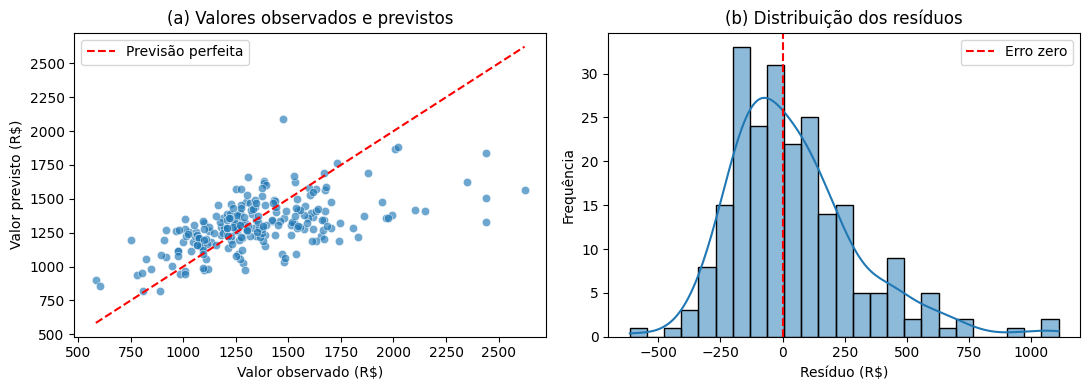

In [111]:
real = y_test_final.to_numpy()
previsto = np.asarray(pred_2025)

# Resíduo: observado - previsto
residuos = real - previsto

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Painel A: previsto vs. real
sns.scatterplot(
    x=real,
    y=previsto,
    ax=axes[0],
    alpha=0.65
)

limites = [
    min(real.min(), previsto.min()),
    max(real.max(), previsto.max())
]

axes[0].plot(
    limites, limites,
    'r--',
    label='Previsão perfeita'
)

axes[0].set_xlabel('Valor observado (R$)')
axes[0].set_ylabel('Valor previsto (R$)')
axes[0].set_title('(a) Valores observados e previstos')
axes[0].legend()

# Painel B: distribuição dos resíduos
sns.histplot(
    residuos,
    bins=25,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(
    0,
    color='red',
    linestyle='--',
    label='Erro zero'
)

axes[1].set_xlabel('Resíduo (R$)')
axes[1].set_ylabel('Frequência')
axes[1].set_title('(b) Distribuição dos resíduos')
axes[1].legend()

plt.tight_layout()


plt.savefig(
    'diagnostico_xg_2025.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# SHAP

Descrição do comportamento preditivo aprendido pelo modelo

In [112]:
import shap

print(shap.__version__)

0.54.1


In [113]:
nomes_variaveis = {
    'media_permanencia': 'Média de permanência',
    'internacoes_1000hab': 'Internações por mil habitantes',
    'populacao': 'População',
    'renda_per_capita': 'Renda per capita',
    'perc_esgotamento_adequado': 'Esgotamento adequado',
    'obitos_1000internacoes': 'Óbitos por mil internações',
    'tx_analfabetismo': 'Taxa de analfabetismo',
    'ano': 'Ano',
    'cobertura_plano': 'Cobertura de planos de saúde',
    'razao_cadunico_pop': 'Razão CadÚnico/população',
    'aih_por_internacao': 'AIHs por internação'
}

In [114]:
X_shap_2025 = X_test_final.copy()

explainer_final = shap.TreeExplainer(
    xgb_final
)

shap_values_2025 = explainer_final(
    X_shap_2025
)

In [115]:
import copy

shap_values_pt = copy.copy(shap_values_2025)

shap_values_pt.feature_names = [
    nomes_variaveis.get(col, col)
    for col in X_test_final.columns
]

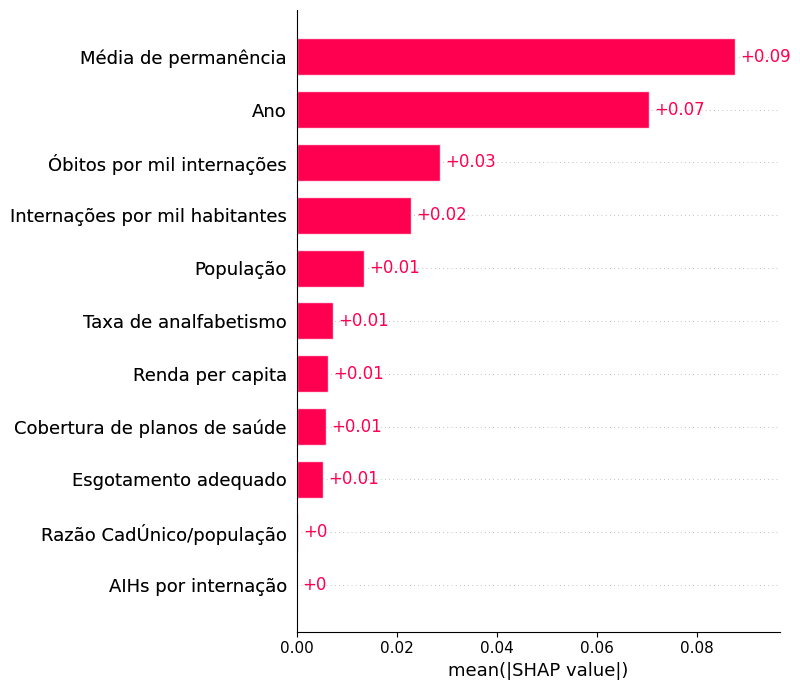

In [116]:
shap.plots.bar(
    shap_values_pt,
    max_display=len(X_test_final.columns),
    show=False
)

plt.tight_layout()
plt.show()

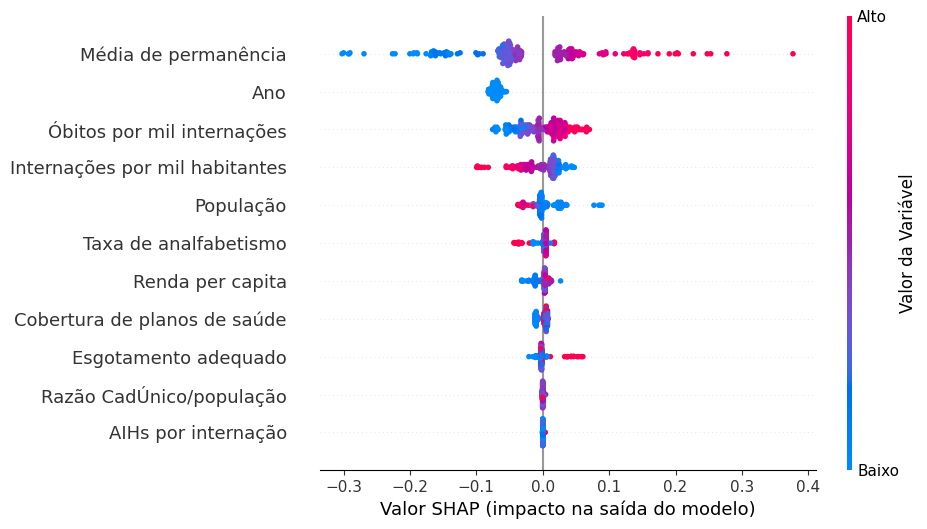

In [117]:
shap.plots.beeswarm(
    shap_values_pt,
    max_display=len(X_test_final.columns),
    show=False
)

# Traduzindo o eixo X
plt.xlabel("Valor SHAP (impacto na saída do modelo)")

# Traduzindo a barra de cores (Colorbar)
fig = plt.gcf()
cax = fig.axes[-1]
cax.set_ylabel("Valor da Variável")
cax.set_yticklabels(['Baixo', 'Alto'])

plt.savefig(
    'shap_xg_2025.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

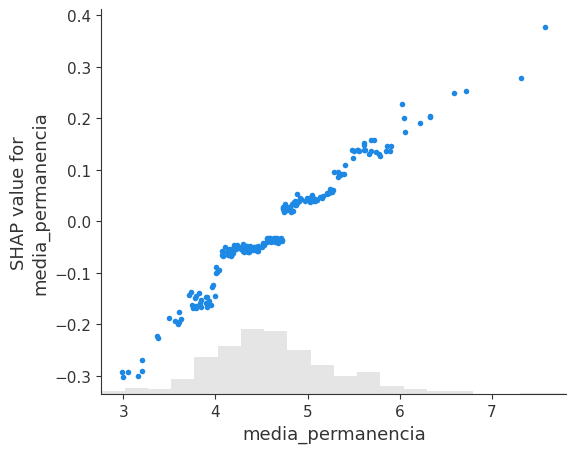

In [118]:
shap.plots.scatter(
    shap_values_2025[:, 'media_permanencia']
)

A média de permanência apresenta uma relação fortemente crescente. Valores menores estão associados a contribuições SHAP negativas; conforme a permanência aumenta, a contribuição passa para positiva e cresce bastante. Nos municípios com médias acima de 6–7 dias aparecem algumas das maiores contribuições positivas.

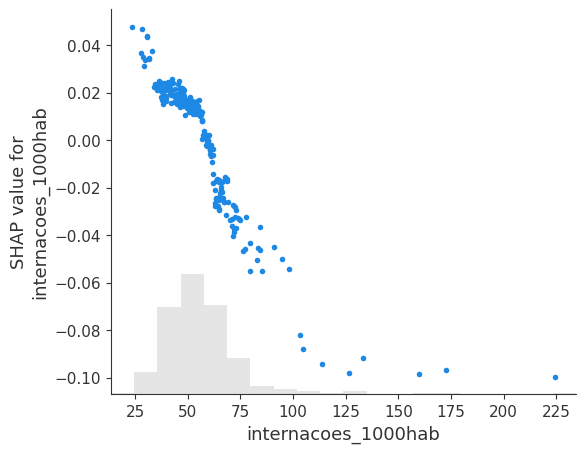

In [119]:
shap.plots.scatter(
    shap_values_2025[:, 'internacoes_1000hab']
)

Taxas menores de internação apresentam contribuições positivas; conforme a taxa aumenta, os valores SHAP tornam-se progressivamente negativos.

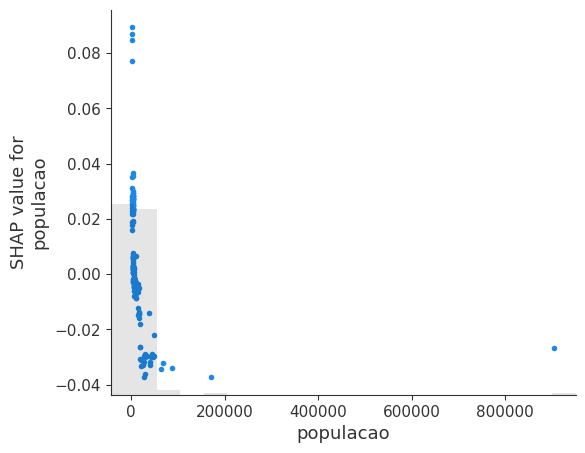

In [120]:
shap.plots.scatter(
    shap_values_2025[:, 'populacao']
)

Os maiores municípios apresentam contribuição negativa, enquanto entre os municípios pequenos existe uma dispersão muito maior.

# Análise dos resíduos

Quais municípios tiveram custo médio em 2025 muito diferente daquele esperado pelo modelo?

In [121]:
resultados_2025 = teste_final[
    [
        'codigo_ibge',
        'municipio',
        'populacao',
        'Internacoes',
        target
    ]
].copy()

resultados_2025['custo_previsto'] = pred_2025

resultados_2025['residuo'] = (
    resultados_2025[target]
    - resultados_2025['custo_previsto']
)

resultados_2025['erro_absoluto'] = abs(
    resultados_2025['residuo']
)

In [122]:
resultados_2025['residuo'].describe()

,residuo
count,224.000000
mean,46.874878
std,260.029262
min,-614.167674
25%,-137.199642
50%,-0.091176
75%,162.764280
max,1110.238404


Média 46,87

Mediana -0,09

In [123]:
print(
    'Assimetria dos resíduos:',
    resultados_2025['residuo'].skew()
)

Assimetria dos resíduos: 1.1427965067005177


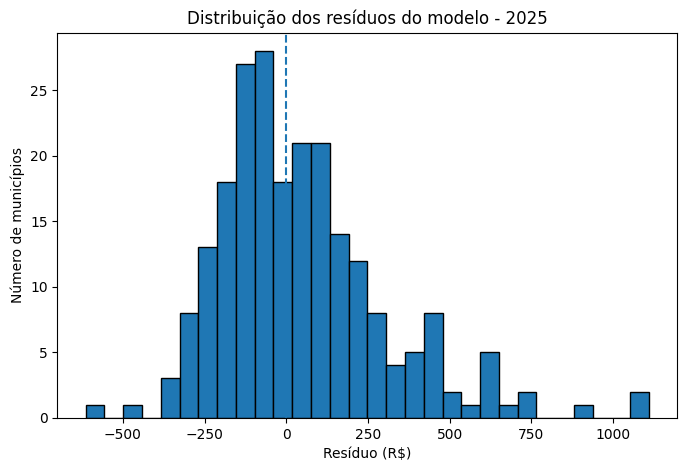

In [124]:
plt.figure(figsize=(8, 5))

plt.hist(
    resultados_2025['residuo'],
    bins=30,
    edgecolor='black'
)

plt.axvline(
    0,
    linestyle='--'
)

plt.xlabel('Resíduo (R$)')
plt.ylabel('Número de municípios')
plt.title('Distribuição dos resíduos do modelo - 2025')

plt.show()

## Identificação de Outliers

In [125]:
q1 = resultados_2025['residuo'].quantile(0.25)
q3 = resultados_2025['residuo'].quantile(0.75)

iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print(f'Q1: R$ {q1:.2f}')
print(f'Q3: R$ {q3:.2f}')
print(f'IQR: R$ {iqr:.2f}')
print(f'Limite inferior: R$ {limite_inferior:.2f}')
print(f'Limite superior: R$ {limite_superior:.2f}')

Q1: R$ -137.20
Q3: R$ 162.76
IQR: R$ 299.96
Limite inferior: R$ -587.15
Limite superior: R$ 612.71


In [126]:
resultados_2025['anomalia'] = 'Não'

resultados_2025.loc[
    resultados_2025['residuo'] > limite_superior,
    'anomalia'
] = 'Acima do esperado'

resultados_2025.loc[
    resultados_2025['residuo'] < limite_inferior,
    'anomalia'
] = 'Abaixo do esperado'

In [127]:
resultados_2025['anomalia'].value_counts()

,count
anomalia,
Não,216
Acima do esperado,7
Abaixo do esperado,1


In [128]:
anomalias_2025 = (
    resultados_2025[
        resultados_2025['anomalia'] != 'Não'
    ]
    .sort_values(
        'residuo',
        ascending=False
    )
)

anomalias_2025[
    [
        'municipio',
        'populacao',
        'Internacoes',
        target,
        'custo_previsto',
        'residuo',
        'anomalia'
    ]
]

,municipio,populacao,Internacoes,valor_medio_internacao_real,custo_previsto,residuo,anomalia
687,FRANCISCO MACEDO,2985.0,88,2438.015381,1327.776978,1110.238404,Acima do esperado
1519,SAO JOAO DA CANABRAVA,4359.0,169,2623.625249,1562.415405,1061.209844,Acima do esperado
1527,SAO JOAO DA FRONTEIRA,5608.0,176,2439.908078,1506.013184,933.894895,Acima do esperado
39,ALEGRETE DO PIAUI,4707.0,149,2151.988815,1408.236694,743.752121,Acima do esperado
1615,SAO MIGUEL DA BAIXA GRANDE,2299.0,126,2348.281295,1620.900879,727.380416,Acima do esperado
711,GEMINIANO,5604.0,228,2103.241360,1415.119629,688.121731,Acima do esperado
1447,SANTO ANTONIO DE LISBOA,5930.0,225,1991.445297,1378.440186,613.005111,Acima do esperado
1391,RIO GRANDE DO PIAUI,5845.0,222,1475.532033,2089.699707,-614.167674,Abaixo do esperado


In [129]:
faixas_pop = [
    0,
    5000,
    10000,
    20000,
    50000,
    100000,
    np.inf
]

nomes_faixas = [
    'Até 5 mil',
    '5–10 mil',
    '10–20 mil',
    '20–50 mil',
    '50–100 mil',
    '>100 mil'
]

resultados_2025['porte'] = pd.cut(
    resultados_2025['populacao'],
    bins=faixas_pop,
    labels=nomes_faixas,
    include_lowest=True
)

In [130]:
resumo_porte = (
    resultados_2025
    .groupby('porte', observed=True)
    .agg(
        municipios=('municipio', 'count'),
        mae=('erro_absoluto', 'mean'),
        mediana_erro=('erro_absoluto', 'median'),
        residuo_mediano=('residuo', 'median'),
        anomalias_positivas=(
            'anomalia',
            lambda x: (x == 'Acima do esperado').sum()
        )
    )
)

resumo_porte['perc_anomalias_positivas'] = (
    resumo_porte['anomalias_positivas']
    / resumo_porte['municipios']
    * 100
)

resumo_porte

,municipios,mae,mediana_erro,residuo_mediano,anomalias_positivas,perc_anomalias_positivas
porte,,,,,,
Até 5 mil,77,237.851309,197.042140,24.232322,4,5.194805
5–10 mil,82,199.252112,142.721261,35.885666,3,3.658537
10–20 mil,38,133.828306,129.110427,-61.512388,0,0.000000
20–50 mil,21,132.975773,131.758620,-53.007685,0,0.000000
50–100 mil,4,126.672222,118.416454,57.944301,0,0.000000
>100 mil,2,106.103116,106.103116,-14.378149,0,0.000000


Todos os resíduos positivos extremos ocorreram em municípios com menos de 10 mil habitantes

In [131]:
faixas_internacoes = [
    0,
    100,
    200,
    500,
    1000,
    np.inf
]

nomes_internacoes = [
    'Até 100',
    '101–200',
    '201–500',
    '501–1000',
    '>1000'
]

resultados_2025['faixa_internacoes'] = pd.cut(
    resultados_2025['Internacoes'],
    bins=faixas_internacoes,
    labels=nomes_internacoes,
    include_lowest=True
)

In [132]:
resumo_internacoes = (
    resultados_2025
    .groupby('faixa_internacoes', observed=True)
    .agg(
        municipios=('municipio', 'count'),
        mae=('erro_absoluto', 'mean'),
        mediana_erro=('erro_absoluto', 'median'),
        anomalias_positivas=(
            'anomalia',
            lambda x: (x == 'Acima do esperado').sum()
        )
    )
)

resumo_internacoes['perc_anomalias_positivas'] = (
    resumo_internacoes['anomalias_positivas']
    / resumo_internacoes['municipios']
    * 100
)

resumo_internacoes

,municipios,mae,mediana_erro,anomalias_positivas,perc_anomalias_positivas
faixa_internacoes,,,,,
Até 100,3,431.001332,143.658225,1,33.333333
101–200,46,285.104855,228.224618,4,8.695652
201–500,108,186.179040,156.132522,2,1.851852
501–1000,24,147.509107,131.107625,0,0.000000
>1000,43,120.807065,119.929831,0,0.000000


Por que o modelo estimou esse valor para Francisco Macedo em 2025?



```
população: 2.985
internações: 88
custo observado: R$ 2.438,02
custo previsto: R$ 1.390.21
resíduo: +R$ 1.047.81
```



In [133]:
pos_francisco = (
    teste_final
    .reset_index(drop=True)
    .query("municipio == 'FRANCISCO MACEDO'")
    .index[0]
)

print(pos_francisco)

85


In [134]:
teste_final.reset_index(drop=True).iloc[
    pos_francisco
][
    ['municipio', 'populacao', 'Internacoes',
     'valor_medio_internacao_real']
]

,85
municipio,FRANCISCO MACEDO
populacao,2985.0
Internacoes,88
valor_medio_internacao_real,2438.015381


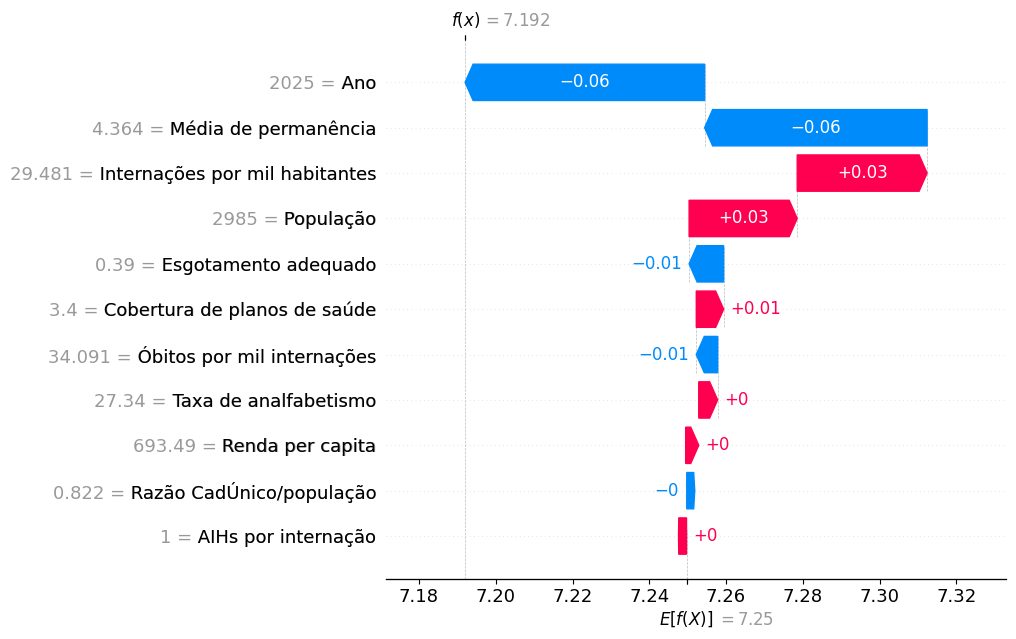

In [135]:
shap.plots.waterfall(
    shap_values_pt[pos_francisco],
    max_display=len(X_test_final.columns),
    show=False
)

plt.savefig('shap_xg_francisco.png', dpi=300, bbox_inches='tight')

plt.show()